# Week 7 - Clipping

In this lesson we will learn how to clip different geometries.

By the end of this lesson, you will be able to:

- reproject geo-dataframes so they share the same CRS 
- clip a `geopandas.GeoDataFrame` to the polygons of another one using `geopandas.clip()`
- subset tabular data before applying geospatial operations
- decide when to clip to a bounding box instead of the exact polygons

## About the data

We will use three datasets. Put each unzipped folder inside a `data/` folder at the same level as this notebook.

1. **US states**: the 2026 [TIGER shapefile of the US states](https://www.census.gov/geographies/mapping-files/time-series/geo/tiger-line-file.2026.html#form-dropdown-790442341) from the United States Census Bureau. You already have this dataset in your computer. 

2. **Populated places**: [Natural Earth's medium-scale populated places dataset (1:50m)](https://www.naturalearthdata.com/downloads/50m-cultural-vectors/). Under "Populated Places", download the simple version (the one that says "simple (less columns)"). You will get a `ne_50m_populated_places_simple` folder.

3. **Roads**: [Natural Earth's large-scale roads dataset (1:10m)](https://www.naturalearthdata.com/downloads/10m-cultural-vectors/roads/). Download the shapefile. You will get a `ne_10m_roads` folder.

Read the [lesson's "About the data" section](https://meds-eds-220.github.io/MEDS-eds-220-course/book/chapters/lesson-13-clipping/lesson-13-clipping.html#about-the-data) for more information about the datasets, including the column descriptions of the US states shapefile.

## Import data

Let's start by loading our libraries and then importing the datasets we will use.

In [2]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

from shapely.geometry import box  # To create polygon bounding box


pd.set_option("display.max.columns", None)

# -------------------------------------------------------
# === MODIFY AS NEEDED TO IMPORT YOUR DATA ===

# Import states polygons
states = gpd.read_file(os.path.join('data', 
                                    'tl_2026_us_state', 
                                    'tl_2026_us_state.shp'))

# Import Natural Earth populated places points
places = gpd.read_file(os.path.join('data',
                                    'ne_50m_populated_places_simple',
                                    'ne_50m_populated_places_simple.shp')
                                    )

# Import roads lines
roads = gpd.read_file(os.path.join('data',
                                   'ne_10m_roads',
                                   'ne_10m_roads.shp')
                                   )

## Check-in (complete before class)
Use a `for` loop to iterate over the three geo-dataframes we imported and change their column names to lowercase.

In [12]:
for df in [states, places, roads]:
    df.columns = df.columns.str.lower()

## Prepare Alaska multipolygon

Let’s take a look at our `states` geo-dataframe. Since this is a geospatial dataset, exploration should include at least checking the head of the dataset, plotting the data, and looking at its CRS.



In [13]:
states.head()

,region,division,statefp,statens,geoid,geoidfq,stusps,name,lsad,mtfcc,funcstat,aland,awater,intptlat,intptlon,geometry
0,1,2,36,01779796,36,0400000US36,NY,New York,00,G4000,A,122049230845,19256680224,+42.9133974,-075.5962723,"MULTIPOLYGON (((-74.04075 40.70017, -74.04073 ..."
1,4,8,32,01779793,32,0400000US32,NV,Nevada,00,G4000,A,284537080522,1839846018,+39.3310928,-116.6151469,"POLYGON ((-119.32418 41.99392, -119.32362 41.9..."
2,4,9,02,01785533,02,0400000US02,AK,Alaska,00,G4000,A,1479942808337,244276695297,+63.3469818,-152.8385657,"MULTIPOLYGON (((-167.55823 60.22436, -167.5567..."
3,9,0,60,01802701,60,0400000US60,AS,American Samoa,00,G4000,A,197759077,1307243766,-14.2668475,-170.6671854,"MULTIPOLYGON (((-168.22527 -14.53591, -168.224..."
4,1,1,50,01779802,50,0400000US50,VT,Vermont,00,G4000,A,23872617229,1030604623,+44.0589536,-072.6710173,"POLYGON ((-72.04187 44.15665, -72.0418 44.1566..."


In [14]:
states.crs

<Geographic 2D CRS: EPSG:4269>
Name: NAD83
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: North America - onshore and offshore: Canada - Alberta; British Columbia; Manitoba; New Brunswick; Newfoundland and Labrador; Northwest Territories; Nova Scotia; Nunavut; Ontario; Prince Edward Island; Quebec; Saskatchewan; Yukon. Puerto Rico. United States (USA) - Alabama; Alaska; Arizona; Arkansas; California; Colorado; Connecticut; Delaware; Florida; Georgia; Hawaii; Idaho; Illinois; Indiana; Iowa; Kansas; Kentucky; Louisiana; Maine; Maryland; Massachusetts; Michigan; Minnesota; Mississippi; Missouri; Montana; Nebraska; Nevada; New Hampshire; New Jersey; New Mexico; New York; North Carolina; North Dakota; Ohio; Oklahoma; Oregon; Pennsylvania; Rhode Island; South Carolina; South Dakota; Tennessee; Texas; Utah; Vermont; Virginia; Washington; West Virginia; Wisconsin; Wyoming. US Virgin Islands. British Virgin Islands

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

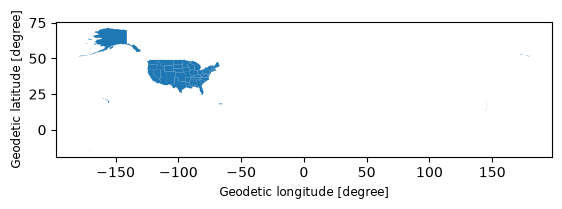

In [15]:
states.plot()

In [16]:
# Only interested in Alaska
alaska = states[states['name'] == 'Alaska']

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

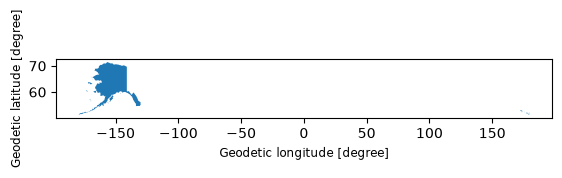

In [17]:
alaska.plot()

Notice that the way the Alaska multipolygon is plotted under the NAD83/EPSG:4269 CRS separates the islands and unnaturally elongates the map. This happens because the westernmost Aleutian Islands cross the 180° meridian (the antimeridian): their longitudes jump from -180° to about +172°, so they are drawn on the opposite side of the plot. To fix this, we will reproject the Alaska geo-dataframe to the EPSG:3338 CRS. This CRS is a projected CRS, better suited for working with data from Alaska:



In [18]:
# Reproject to CRS optimized for Alaska
alaska = alaska.to_crs('epsg:3338')

# Inspect the new CRS
print('Is this CRS projected? ', alaska.crs.is_projected)
alaska.crs

Is this CRS projected?  True


<Projected CRS: EPSG:3338>
Name: NAD83 / Alaska Albers
Axis Info [cartesian]:
- X[east]: Easting (metre)
- Y[north]: Northing (metre)
Area of Use:
- name: United States (USA) - Alaska.
- bounds: (172.42, 51.3, -129.99, 71.4)
Coordinate Operation:
- name: Alaska Albers (meter)
- method: Albers Equal Area
Datum: North American Datum 1983
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

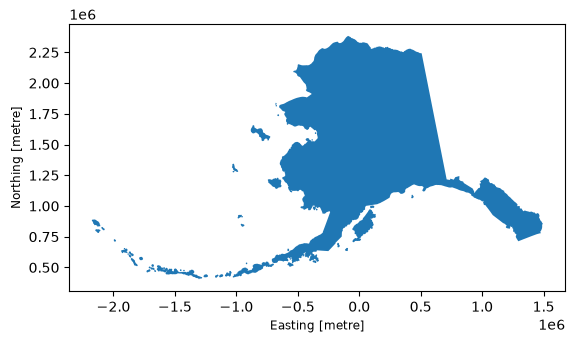

In [19]:
alaska.plot()

## Prepare populated places points



In [20]:
places.head()

,scalerank,natscale,labelrank,featurecla,name,namepar,namealt,nameascii,adm0cap,capalt,capin,worldcity,megacity,sov0name,sov_a3,adm0name,adm0_a3,adm1name,iso_a2,note,latitude,longitude,pop_max,pop_min,pop_other,rank_max,rank_min,meganame,ls_name,min_zoom,ne_id,geometry
0,10,1,5,Admin-1 region capital,Bombo,NaN,NaN,Bombo,0,0,NaN,0,0,Uganda,UGA,Uganda,UGA,Bamunanika,UG,NaN,0.583299,32.533300,75000,21000,0.0,8,7,NaN,NaN,7.0,1159113923,POINT (32.5333 0.5833)
1,10,1,5,Admin-1 region capital,Fort Portal,NaN,NaN,Fort Portal,0,0,NaN,0,0,Uganda,UGA,Uganda,UGA,Kabarole,UG,NaN,0.671004,30.275002,42670,42670,0.0,7,7,NaN,NaN,7.0,1159113959,POINT (30.275 0.671)
2,10,1,3,Admin-1 region capital,Potenza,NaN,NaN,Potenza,0,0,NaN,0,0,Italy,ITA,Italy,ITA,Basilicata,IT,NaN,40.642002,15.798997,69060,69060,0.0,8,8,NaN,NaN,7.0,1159117259,POINT (15.799 40.642)
3,10,1,3,Admin-1 region capital,Campobasso,NaN,NaN,Campobasso,0,0,NaN,0,0,Italy,ITA,Italy,ITA,Molise,IT,NaN,41.562999,14.655997,50762,50762,0.0,8,8,NaN,NaN,7.0,1159117283,POINT (14.656 41.563)
4,10,1,3,Admin-1 region capital,Aosta,NaN,NaN,Aosta,0,0,NaN,0,0,Italy,ITA,Italy,ITA,Valle d'Aosta,IT,NaN,45.737001,7.315003,34062,34062,0.0,7,7,NaN,NaN,7.0,1159117361,POINT (7.315 45.737)


In [21]:
places.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

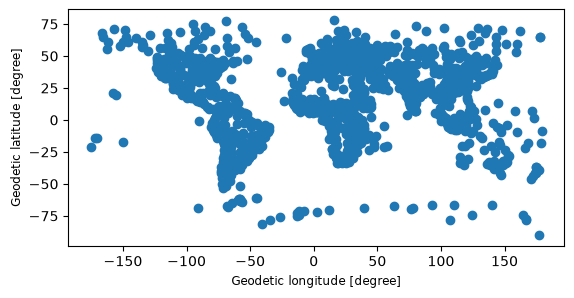

In [22]:
places.plot()

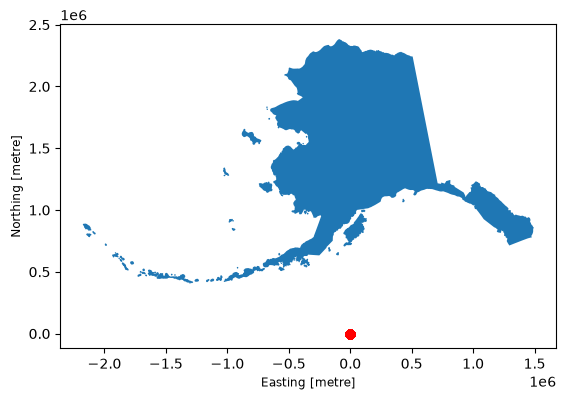

In [23]:
# Trouble
fig, ax = plt.subplots()

alaska.plot(ax=ax)
places.plot(ax=ax, color='red')

plt.show()

In [24]:
places = places.to_crs(alaska.crs)

assert alaska.crs == places.crs

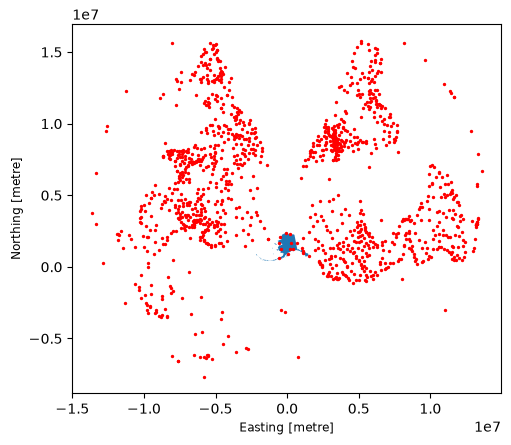

In [26]:
fig, ax = plt.subplots()

alaska.plot(ax=ax)
places.plot(ax=ax, color='red', markersize=2)

plt.show()

## Clipping

**Clipping** means using a polygon (or polygons) to keep only the parts of the geometries that fall inside them. Clipping a `geopandas.GeoDataFrame` is simple using the geopandas clip() function. The general syntax is:

```
updated_geodf = geopandas.clip(geodf, mask)
```

where:
- `updated_geodf` is the output of the function: the intersection of the geometries in `geodf` with `mask`,
- `geodf` is the `geopandas.GeoDataFrame` we want to clip,
- `mask` is a `geopandas.GeoDataFrame` with the polygon(s) we want to use for clipping (we will see later that it can also be a bounding box). This `mask` must be in the same CRS as `geodf`!


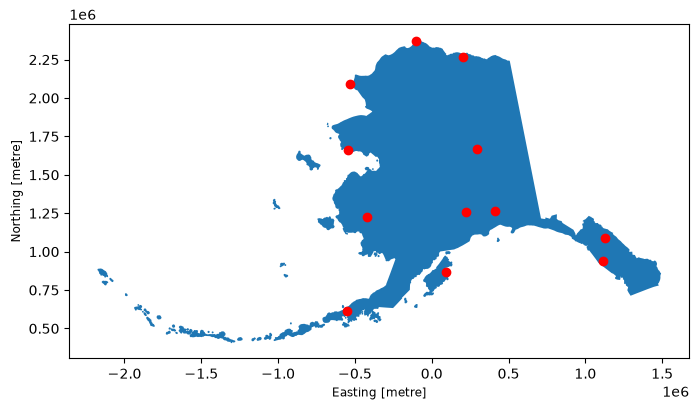

In [27]:
# clip populated places to Alaska multipolygon
ak_places = gpd.clip(places, alaska)

fig, ax = plt.subplots(figsize=(8,6))

alaska.plot(ax=ax)

ak_places.plot(ax=ax,
               color = 'red')

plt.show()

## Prepare roads



In [28]:
roads.head()

,scalerank,featurecla,type,sov_a3,note,edited,name,namealt,namealtt,routeraw,question,length_km,toll,ne_part,label,label2,local,localtype,localalt,labelrank,ignore,add,rwdb_rd_id,orig_fid,prefix,uident,continent,expressway,level,min_zoom,min_label,geometry
0,8,Road,Secondary Highway,CAN,NaN,"Version 1.5: Changed alignment, a few adds in ...",NaN,NaN,NaN,NaN,0,3,0,ne_1d4_original,NaN,NaN,NaN,NaN,NaN,0,0,0,0,0,NaN,314705,North America,0,NaN,7.1,9.6,"LINESTRING (-133.32533 62.21571, -133.31664 62..."
1,7,Road,Secondary Highway,USA,NaN,"Version 1.5: Changed alignment, a few adds in ...",83,NaN,NaN,NaN,0,164,0,ne_1d4_original,NaN,NaN,NaN,NaN,NaN,0,0,0,0,0,NaN,108105,North America,0,Federal,7.0,8.6,"LINESTRING (-100.50543 42.80753, -100.53495 42..."
2,7,Road,Secondary Highway,USA,NaN,"Version 1.5: Changed alignment, a few adds in ...",840,NaN,NaN,NaN,0,98,0,ne_1d4_original,NaN,NaN,NaN,NaN,NaN,0,0,0,0,0,NaN,0,North America,0,U/C,7.0,9.5,"LINESTRING (-87.27432 36.02439, -87.22916 35.9..."
3,8,Road,Secondary Highway,USA,NaN,"Version 1.5: Changed alignment, a few adds in ...",151,NaN,NaN,NaN,0,17,0,ne_1d4_original,NaN,NaN,NaN,NaN,NaN,0,0,0,0,0,NaN,0,North America,0,Federal,7.1,9.6,"LINESTRING (-87.72757 44.15165, -87.57301 44.1..."
4,6,Road,Major Highway,USA,NaN,"Version 1.5: Changed alignment, a few adds in ...",GSP,NaN,NaN,NaN,0,33,1,ne_1d4_original,NaN,NaN,NaN,NaN,NaN,0,0,0,0,0,NaN,311305,North America,1,State,6.0,8.5,"MULTILINESTRING ((-74.7592 39.14301, -74.67359..."


In [29]:
roads.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

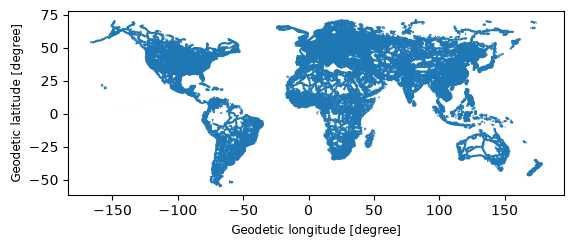

In [30]:
roads.plot()

In [31]:
usa_roads = roads[roads['sov_a3'] == 'USA']

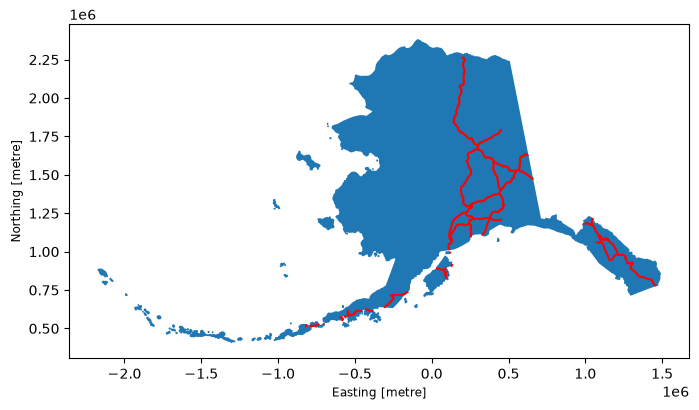

In [32]:
# clip usa_roads to alaska
usa_roads = usa_roads.to_crs(alaska.crs)
ak_roads = gpd.clip(usa_roads, alaska)

fig, ax = plt.subplots(figsize=(8,6))

alaska.plot(ax=ax)
ak_roads.plot(ax=ax,
              color = 'red')

plt.show()

Notice the short, disconnected segments in the southwest? Many of these “roads” are ferry routes that run over water. Clipping to the `alaska` polygons keeps only the pieces that cross land, so clipping exactly to the polygons isn’t what we want here.



## Clipping with a bounding box

In [33]:
alaska.total_bounds

array([-2175729.73162241,   404545.10791528,  1493082.30904445,
        2383808.43520816])

In [34]:
ak_complete_roads = gpd.clip(usa_roads, alaska.total_bounds)

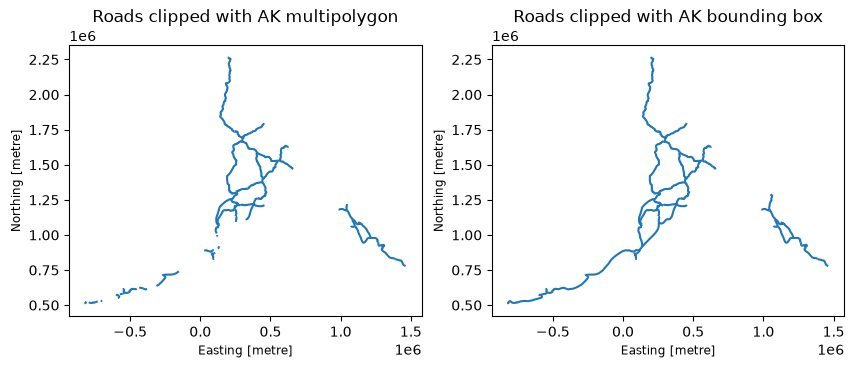

In [36]:
# Compare the two clipping methods
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10,10))

ak_roads.plot(ax=ax1)
ax1.set_title('Roads clipped with AK multipolygon')

ak_complete_roads.plot(ax=ax2)
ax2.set_title('Roads clipped with AK bounding box')

plt.show()

## Measuring length

To understand the difference between the two clips, we will compare the `lengths` of their roads. Geo-dataframes have a length attribute that calculates the length of each line from its geometry, **in the units of the CRS**. Let’s try it on one road in Alaska, the road with index 1138:



In [40]:
print(usa_roads.loc[[1138]].length)

1138    287473.410936
dtype: float64


To measure lengths, we first need to reproject to a projected CRS whose units are meters. Let’s use the EPSG:3338 CRS for Alaska:



In [42]:
# Reproject to the Alaska CRS and convert meters to kilometers
print(usa_roads.loc[[1138]].to_crs('epsg:3338').length / 1000)

1138    287.473411
dtype: float64


## How does clipping affect the data?



In [43]:
print('Number of roads (polygon clip):', len(ak_roads))
print('Number of roads (bbox clip):   ', len(ak_complete_roads))

# Divide by 1000 to convert meters to kilometers
print('Total length in km (polygon clip):', round(ak_roads.length.sum() / 1000))
print('Total length in km (bbox clip):   ', round(ak_complete_roads.length.sum() / 1000))

Number of roads (polygon clip): 56
Number of roads (bbox clip):    56
Total length in km (polygon clip): 6069
Total length in km (bbox clip):    7111


Both geo-dataframes have the same number of rows: clipping to the polygons did not drop any road. Instead, `gpd.clip()` cut the roads that cross the coastline, so the polygon clip has about 1,000 fewer kilometers of roads. The difference is in the geometries, not in the number of rows.



Let’s zoom in on road 1138, the route we measured earlier, to see what happened. It’s a ferry route in the eastern Aleutian Islands. Let’s plot it from each clipped geo-dataframe:



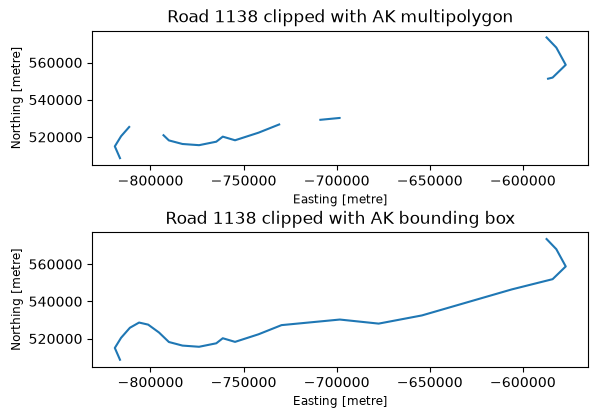

In [44]:
fig, (ax1, ax2) = plt.subplots(2, 1)

ak_roads.loc[[1138]].plot(ax=ax1)
ax1.set_title('Road 1138 clipped with AK multipolygon')

ak_complete_roads.loc[[1138]].plot(ax=ax2)
ax2.set_title('Road 1138 clipped with AK bounding box')

plt.show()

In [45]:
print('Length in km (polygon clip):', round(ak_roads.length[1138] / 1000, 1))
print('Length in km (bbox clip):   ', round(ak_complete_roads.length[1138] / 1000, 1))

print('Geometry type (polygon clip):', ak_roads.geom_type[1138])
print('Geometry type (bbox clip):   ', ak_complete_roads.geom_type[1138])

Length in km (polygon clip): 131.6
Length in km (bbox clip):    287.5
Geometry type (polygon clip): MultiLineString
Geometry type (bbox clip):    LineString


The polygon clip kept only about 132 of the route’s 287 km. It also changed the geometry type: the route crosses the coastline several times, so the polygon clip cut it into several pieces and turned the `LineString` into a `MultiLineString`.



In [46]:
ak_roads.loc[[1138]]

,scalerank,featurecla,type,sov_a3,note,edited,name,namealt,namealtt,routeraw,question,length_km,toll,ne_part,label,label2,local,localtype,localalt,labelrank,ignore,add,rwdb_rd_id,orig_fid,prefix,uident,continent,expressway,level,min_zoom,min_label,geometry
1138,7,Ferry,Ferry Route,USA,NaN,New in version 2.0.0,NaN,NaN,NaN,NaN,0,435,0,ne_1d4_original,NaN,NaN,NaN,NaN,NaN,0,0,0,0,0,NaN,4305,North America,0,Ferry,7.0,9.5,"MULTILINESTRING ((-587641.011 573877.088, -582..."


In [47]:
ak_complete_roads.loc[[1138]]

,scalerank,featurecla,type,sov_a3,note,edited,name,namealt,namealtt,routeraw,question,length_km,toll,ne_part,label,label2,local,localtype,localalt,labelrank,ignore,add,rwdb_rd_id,orig_fid,prefix,uident,continent,expressway,level,min_zoom,min_label,geometry
1138,7,Ferry,Ferry Route,USA,NaN,New in version 2.0.0,NaN,NaN,NaN,NaN,0,435,0,ne_1d4_original,NaN,NaN,NaN,NaN,NaN,0,0,0,0,0,NaN,4305,North America,0,Ferry,7.0,9.5,"LINESTRING (-587641.011 573877.088, -582019.27..."


## Plot

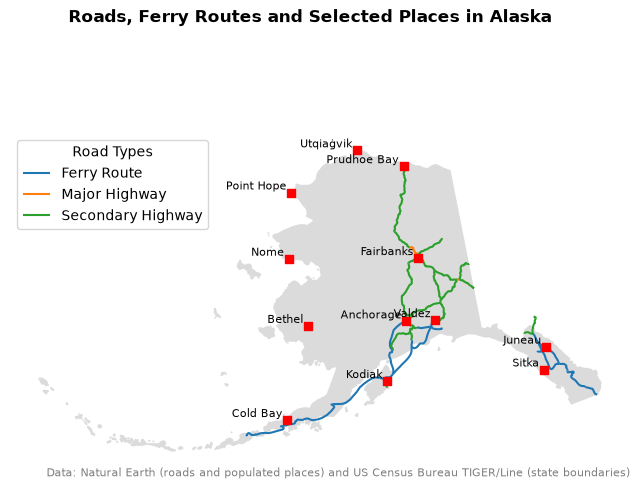

In [59]:
fig, ax = plt.subplots(figsize = (8,6))

ax.axis('off')

alaska.plot(ax=ax,
            color = 'lightgrey',
            alpha=0.8,
            zorder=1)

ak_complete_roads.plot(ax=ax,
                       column = 'type',
                       legend=True,
                       legend_kwds={'title':'Road Types',
                                    'loc':'upper left'},
                        zorder = 2)

ak_places.plot(ax=ax,
               marker = 's',
               color='red',
               zorder = 3)

# Add city names as text annotations
for x, y, name in zip(ak_places.geometry.x, ak_places.geometry.y, ak_places['name']):
    ax.text(x-30000, y+20000, name, fontsize=8, ha='right')

# Add data sources below the map
ax.annotate("Data: Natural Earth (roads and populated places) and US Census Bureau TIGER/Line (state boundaries)",
            xy=(1, 0), xycoords='axes fraction',  # Bottom-right corner of the axes
            ha='right', va='top', fontsize=8, color='gray')

plt.suptitle('Roads, Ferry Routes and Selected Places in Alaska', fontweight = 'bold')
plt.show()